# Mixed-effects models relating BAI to within-stem growth asymmetry

This notebook reproduces the BAI-|TGAI| analyses for the main analysis, the site-specific detrended analysis, and the sensitivity analysis requiring at least five valid SFS-NFS core pairs per site. It generates Figures 3c-d, S7, and S10c-d and Tables S2-S4.


In [7]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
CRU_PRE = DATA_DIR / "climate" / "cru_ts4.07.1901.2022.pre.dat.nc"
CRU_TMP = DATA_DIR / "climate" / "cru_ts4.07.1901.2022.tmp.dat.nc"

MAIN_BAI_DIR = PROJECT_DIR / "outputs" / "bai"
MAIN_TGAI_FILE = PROJECT_DIR / "outputs" / "tables" / "TGAI-ln.csv"
MAIN_SITE_FILE = PROJECT_DIR / "outputs" / "tables" / "site_level_TGAI.csv"

SENSITIVITY_DIR = PROJECT_DIR / "outputs" / "minimum_5_pairs"
SENSITIVITY_BAI_DIR = SENSITIVITY_DIR / "bai"
SENSITIVITY_TGAI_FILE = SENSITIVITY_DIR / "tables" / "annual_TGAI_minimum_5_pairs.csv"
SENSITIVITY_SITE_FILE = SENSITIVITY_DIR / "tables" / "site_level_TGAI_minimum_5_pairs.csv"

FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"
TABLE_DIR = PROJECT_DIR / "outputs" / "tables"
SENSITIVITY_FIGURE_DIR = SENSITIVITY_DIR / "figures"
SENSITIVITY_TABLE_DIR = SENSITIVITY_DIR / "tables"

for directory in (FIGURE_DIR, TABLE_DIR, SENSITIVITY_FIGURE_DIR, SENSITIVITY_TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

START_YEAR = 1901
END_YEAR = 2000
GROWING_SEASON_MONTHS = [3, 4, 5, 6, 7, 8, 9, 10]


## 1. Load main-analysis BAI data


In [8]:
import os
import pandas as pd
folder = MAIN_BAI_DIR
df_list = []
for file in os.listdir(folder):
    if file.endswith("_mean.csv"):
        file_path = os.path.join(folder, file)
        site = file.replace("BAI_", "").replace("_mean.csv", "")
        df = pd.read_csv(file_path)
        df = df.rename(columns={"Mean_BAI": "BAI"})
        df["site"] = site
        df = df[["Year", "site", "BAI"]]
        df_list.append(df)
if not df_list:
    raise FileNotFoundError(f"No site-level mean BAI files were found in {folder}")
df_bai = pd.concat(df_list, ignore_index=True)
df_bai = df_bai.sort_values(["site", "Year"]).reset_index(drop=True)


## 2. Merge annual BAI and |TGAI|


In [9]:
df_bai1901 = df_bai[df_bai["Year"] >= START_YEAR].reset_index(drop=True)
df_TGAIsite = pd.read_csv(MAIN_TGAI_FILE)

In [10]:
df_TGAI_mean = (df_TGAIsite.groupby(["site", "Year"], as_index=False)
    .agg({
        "Abs_TGAI": "mean",  
        "AI": "mean"      
    })
)


In [11]:
df_TGAI_mean['site'] = df_TGAI_mean['site'].str.lower()
df_bai1901['site'] = df_bai1901['site'].str.lower()
df_bai1901 = df_bai1901[df_bai1901['Year'] <= END_YEAR]
df_me_bai_tgai=pd.merge(df_TGAI_mean, df_bai1901, left_on=['site', 'Year'], right_on=['site', 'Year'], how='inner')

## 3. Add site coordinates and species


In [12]:
df_site = pd.read_csv(MAIN_SITE_FILE)
if "site" not in df_site.columns and "Site_ID" in df_site.columns:
    df_site = df_site.rename(columns={"Site_ID": "site"})
df_site["site"] = df_site["site"].astype(str).str.lower()
site_species = df_site[["site", "Tree_Speci", "Latitude", "Longitude"]].drop_duplicates("site")
df_me_bai_tgai = df_me_bai_tgai.merge(site_species,on='site',how='left')


## 4. Extract annual growing-season climate


In [13]:
import numpy as np,pandas as pd,xarray as xr
if not hasattr(np, "alen"):
    np.alen = lambda a: len(a)
pre_path = CRU_PRE
tmp_path = CRU_TMP

# Growing season: March-October
GS_MONTHS = GROWING_SEASON_MONTHS

# ============================================================
# 1. Site information
# ============================================================
sites=df_me_bai_tgai[['site','Latitude','Longitude']].drop_duplicates('site').copy()
sites=sites.sort_values('site').reset_index(drop=True)

print('Sites =',len(sites))
print(sites.head())

# ============================================================
# 2. Open CRU data
# ============================================================
ds_pre=xr.open_dataset(pre_path)
ds_tmp=xr.open_dataset(tmp_path)

print('\nPRE:')
print(ds_pre)
print('\nTMP:')
print(ds_tmp)

# CRU TS variables normally: pre / tmp
pre=ds_pre['pre']
tmp=ds_tmp['tmp']

# coordinate names
lat_name='lat' if 'lat' in pre.coords else 'latitude'
lon_name='lon' if 'lon' in pre.coords else 'longitude'

# ============================================================
# 3. Handle longitude convention
# ============================================================
site_lon=sites['Longitude'].values.copy()

# If dataset longitude is 0~360, convert site longitude
if float(pre[lon_name].min())>=0:
    site_lon=np.mod(site_lon,360)

site_lat=xr.DataArray(sites['Latitude'].values,dims='site',coords={'site':sites['site'].values})
site_lon=xr.DataArray(site_lon,dims='site',coords={'site':sites['site'].values})

# ============================================================
# 4. Extract nearest CRU grid cell for each site
# ============================================================
pre_site=pre.sel({lat_name:site_lat,lon_name:site_lon},method='nearest')
tmp_site=tmp.sel({lat_name:site_lat,lon_name:site_lon},method='nearest')

# only load selected site data, not full global arrays
pre_site=pre_site.load()
tmp_site=tmp_site.load()

print('\nExtracted PRE shape:',pre_site.shape)
print('Extracted TMP shape:',tmp_site.shape)

# ============================================================
# 5. Growing-season annual GSP / GST
# ============================================================
pre_gs=pre_site.where(pre_site.time.dt.month.isin(GS_MONTHS),drop=True)
tmp_gs=tmp_site.where(tmp_site.time.dt.month.isin(GS_MONTHS),drop=True)

# GSP: sum monthly precipitation
GSP=pre_gs.groupby('time.year').sum('time',skipna=True)

# GST: mean monthly temperature
GST=tmp_gs.groupby('time.year').mean('time',skipna=True)

# ============================================================
# 6. Convert to dataframe
# ============================================================
gsp_df=GSP.to_dataframe(name='GSP').reset_index()[['site','year','GSP']]
gst_df=GST.to_dataframe(name='GST').reset_index()[['site','year','GST']]

climate=gsp_df.merge(gst_df,on=['site','year'],how='outer')
climate=climate.rename(columns={'year':'Year'})

print('\nClimate table:')
print(climate.head())
print(climate[['GSP','GST']].describe())

# ============================================================
# 7. Merge back to df_me_bai_tgai
# ============================================================
df_me_bai_tgai=df_me_bai_tgai.merge(
    climate,
    on=['site','Year'],
    how='left'
)

print('\nFinal dataframe:')
print(df_me_bai_tgai.head())
print('\nMissing GSP =',df_me_bai_tgai['GSP'].isna().sum())
print('Missing GST =',df_me_bai_tgai['GST'].isna().sum())

# ============================================================
# 8. Basic check
# ============================================================
print('\nGSP range:',df_me_bai_tgai.GSP.min(),'~',df_me_bai_tgai.GSP.max(),'mm')
print('GST range:',df_me_bai_tgai.GST.min(),'~',df_me_bai_tgai.GST.max(),'°C')

ds_pre.close()
ds_tmp.close()


Sites = 79
    site  Latitude  Longitude
0  ak048     67.12    -150.08
1  ak049     67.15    -150.08
2  ak050     67.15    -149.13
3  ak054     63.10    -150.00
4  ak056     63.12    -149.00

PRE:
<xarray.Dataset>
Dimensions:  (lon: 720, lat: 360, time: 1464)
Coordinates:
  * lon      (lon) float32 -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
  * lat      (lat) float32 -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * time     (time) datetime64[ns] 1901-01-16 1901-02-15 ... 2022-12-16
Data variables:
    pre      (time, lat, lon) float32 ...
    stn      (time, lat, lon) float64 ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.07 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2304141047. Data generated from:pre.2304141039.dtb
    history:      Fri 14 Apr 12:49:03 BST 2023 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comm

## 5. Main mixed-effects model (Figure 3c-d and Table S2)


Observations = 7586
Sites = 79
Species = 22
|TGAI| mean = 0.3546
GSP mean ± SD = 480.02 ± 273.30 mm
GST mean ± SD = 5.37 ± 5.25 °C
Year range = 1901-2000

================ MIXED MODEL ================
           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  log_BAI   
No. Observations:  7586     Method:              ML        
No. Groups:        22       Scale:               0.1311    
Min. group size:   75       Log-Likelihood:      -3282.8767
Max. group size:   1396     Converged:           Yes       
Mean group size:   344.8                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         5.843    0.127 46.055 0.000  5.594  6.091
Abs_TGAI_c       -0.291    0.041 -7.176 0.000 -0.371 -0.212
GSP_z             0.041    0.014  2.980 0.003  0.014  0.067
Abs_TGAI_c:GSP_z  0.147    0.0

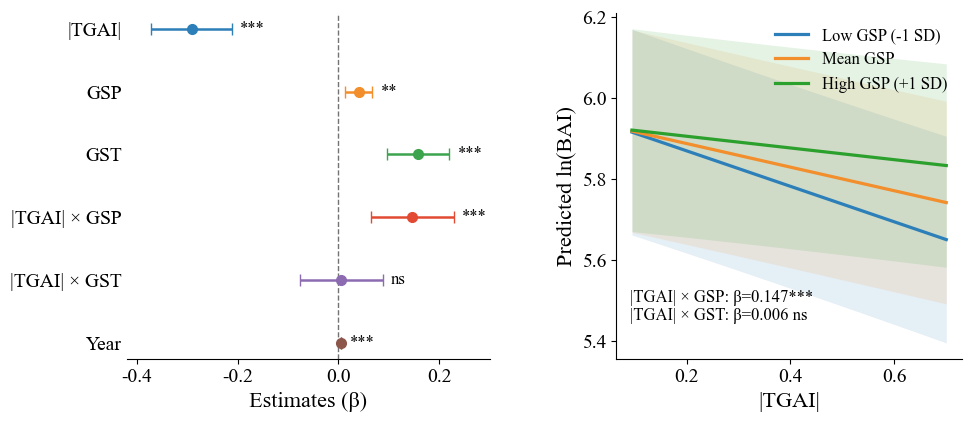

In [14]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams['font.family']='Times New Roman'
plt.rcParams['font.size']=16
plt.rcParams['xtick.labelsize']=14
plt.rcParams['ytick.labelsize']=14
plt.rcParams.update({'font.family':'Times New Roman','font.serif':['Times New Roman'],
                     'mathtext.fontset':'custom','mathtext.rm':'Times New Roman',
                     'mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold',
                     'mathtext.sf':'Times New Roman','axes.unicode_minus':False})

# ==================== Data ====================
df=df_me_bai_tgai[['site','Year','Abs_TGAI','BAI','Tree_Speci','GSP','GST']].copy()
df=df.replace([np.inf,-np.inf],np.nan).dropna()
df=df[(df.BAI>0)&(df.Abs_TGAI>=0)].copy()
df['site']=df.site.astype(str);df['Tree_Speci']=df.Tree_Speci.astype(str);df['log_BAI']=np.log(df.BAI)

tgai_mean=df.Abs_TGAI.mean();gsp_mean,gsp_sd=df.GSP.mean(),df.GSP.std();gst_mean,gst_sd=df.GST.mean(),df.GST.std();year_mean=df.Year.mean()
df['Abs_TGAI_c']=df.Abs_TGAI-tgai_mean
df['GSP_z']=(df.GSP-gsp_mean)/gsp_sd
df['GST_z']=(df.GST-gst_mean)/gst_sd
df['Year_c']=df.Year-year_mean

print('Observations =',len(df))
print('Sites =',df.site.nunique())
print('Species =',df.Tree_Speci.nunique())
print(f'|TGAI| mean = {tgai_mean:.4f}')
print(f'GSP mean ± SD = {gsp_mean:.2f} ± {gsp_sd:.2f} mm')
print(f'GST mean ± SD = {gst_mean:.2f} ± {gst_sd:.2f} °C')
print(f'Year range = {df.Year.min()}-{df.Year.max()}')

# ==================== Mixed model ====================
model=smf.mixedlm('log_BAI ~ Abs_TGAI_c*GSP_z + Abs_TGAI_c*GST_z + Year_c',df,groups=df['Tree_Speci'],re_formula='1',vc_formula={'site':'0+C(site)'})
res=model.fit(reml=False,method='lbfgs',maxiter=5000)
print('\n================ MIXED MODEL ================')
print(res.summary())

# ==================== Model performance ====================
fixed_pred=model.exog@res.fe_params.values
var_fixed=np.var(fixed_pred,ddof=1);var_species=float(res.cov_re.iloc[0,0]);var_site=float(res.vcomp[0]);var_resid=float(res.scale)
var_total=var_fixed+var_species+var_site+var_resid
R2_m=var_fixed/var_total;R2_c=(var_fixed+var_species+var_site)/var_total
print('\n================ MODEL PERFORMANCE ================')
print(f'LogLik = {res.llf:.2f}')
print(f'AIC = {res.aic:.2f}')
print(f'BIC = {res.bic:.2f}')
print(f'Marginal R² = {R2_m:.3f}')
print(f'Conditional R² = {R2_c:.3f}')
print(f'Species variance = {var_species:.4f}')
print(f'Site variance = {var_site:.4f}')
print(f'Residual variance = {var_resid:.4f}')

def star(p):
    if p<0.001:return '***'
    if p<0.01:return '**'
    if p<0.05:return '*'
    return 'ns'

# ==================== Fixed effects ====================
terms=['Abs_TGAI_c','GSP_z','GST_z','Abs_TGAI_c:GSP_z','Abs_TGAI_c:GST_z','Year_c']
labels=['|TGAI|','GSP','GST','|TGAI| × GSP','|TGAI| × GST','Year']
rows=[]
for term,label in zip(terms,labels):
    ci=res.conf_int().loc[term]
    rows.append([label,res.params[term],res.bse[term],ci.iloc[0],ci.iloc[1],res.pvalues[term],star(res.pvalues[term])])
coef=pd.DataFrame(rows,columns=['Variable','Beta','SE','CI_low','CI_high','P','Sig'])
print('\n================ FIXED EFFECTS ================')
print(coef.round(4).to_string(index=False))

# ==================== Simple slopes ====================
b0=res.params['Abs_TGAI_c'];b_gsp=res.params['Abs_TGAI_c:GSP_z']
print('\n================ SIMPLE SLOPES ================')
for z,name in [(-1,'Low GSP (-1 SD)'),(0,'Mean GSP'),(1,'High GSP (+1 SD)')]:
    slope=b0+b_gsp*z
    print(f'{name:18s}: |TGAI| slope on ln(BAI) = {slope:.4f}')

# ==================== Prediction ====================
x=np.linspace(df.Abs_TGAI.quantile(.01),df.Abs_TGAI.quantile(.99),250);xc=x-tgai_mean
fe_names=['Intercept','Abs_TGAI_c','GSP_z','Abs_TGAI_c:GSP_z','GST_z','Abs_TGAI_c:GST_z','Year_c']
beta=res.params[fe_names].values;cov=res.cov_params().loc[fe_names,fe_names].values

def predict_curve(gsp_z):
    X=np.column_stack([np.ones(len(x)),xc,np.full(len(x),gsp_z),xc*gsp_z,np.zeros(len(x)),np.zeros(len(x)),np.zeros(len(x))])
    eta=X@beta
    se=np.sqrt(np.maximum(np.einsum('ij,jk,ik->i',X,cov,X),0))
    return eta,eta-1.96*se,eta+1.96*se

# ==================== Plot ====================
fig,axs=plt.subplots(1,2,figsize=(10,4.5),gridspec_kw={'width_ratios':[1.05,1]})

ax=axs[0]
colors=['#2C7FB8','#F28E2B','#3BA44D','#E34A33','#8C6BB1','#8C564B']
y=np.arange(len(coef))[::-1]
for yi,row,c in zip(y,coef.itertuples(),colors):
    ax.errorbar(row.Beta,yi,xerr=[[row.Beta-row.CI_low],[row.CI_high-row.Beta]],fmt='o',ms=7,lw=1.8,capsize=4,color=c,ecolor=c)
    ax.text(row.CI_high+0.016,yi,row.Sig,ha='left',va='center',fontsize=12)
ax.axvline(0,color='0.45',ls='--',lw=1)
ax.set_yticks(y);ax.set_yticklabels(coef.Variable)
ax.set_xlabel('Estimates (β)')
ax.set_xlim(-0.42,0.30)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False);ax.spines['left'].set_visible(False)
ax.tick_params(axis='y',length=0)

ax=axs[1]
gsp_levels=[(-1,'Low GSP (-1 SD)','#2C7FB8'),(0,'Mean GSP','#F28E2B'),(1,'High GSP (+1 SD)','#2CA02C')]
for level,label,c in gsp_levels:
    pred,lo,hi=predict_curve(level)
    ax.plot(x,pred,lw=2.3,color=c,label=label)
    ax.fill_between(x,lo,hi,color=c,alpha=.12,lw=0)
p1=res.pvalues['Abs_TGAI_c:GSP_z'];p2=res.pvalues['Abs_TGAI_c:GST_z']
ax.text(.04,.20,f'|TGAI| × GSP: β={res.params["Abs_TGAI_c:GSP_z"]:.3f}{star(p1)}\n|TGAI| × GST: β={res.params["Abs_TGAI_c:GST_z"]:.3f} {star(p2)}',
        transform=ax.transAxes,ha='left',va='top',fontsize=12)
ax.set_xlabel('|TGAI|')
ax.set_ylabel('Predicted ln(BAI)')
ax.legend(frameon=False,loc='upper right',fontsize=12)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.tight_layout(w_pad=3)
coef.to_csv(TABLE_DIR / "Table_S2_mixed_model_coefficients.csv", index=False)
plt.savefig(FIGURE_DIR / "Figure_3c_d_BAI_TGAI_mixed_model.png", dpi=600, bbox_inches="tight")
plt.show()

## 6. Site-specific detrended model (Figure S7 and Table S3)


Observations = 7586
Sites = 79
Species = 22

================ TREND CHECK ================
log_BAI        : slope= 0.005892, p=7.342e-33
log_BAI_dt     : slope= 0.000122, p=0.7218
Abs_TGAI       : slope= 0.000669, p=2.583e-22
Abs_TGAI_dt    : slope=-0.000021, p=0.6826
GSP            : slope= 0.215418, p=0.01571
GSP_dt         : slope=-0.098768, p=0.2602
GST            : slope= 0.010489, p=4.183e-10
GST_dt         : slope= 0.001588, p=0.2951

Detrended |TGAI| mean = 0.3546
Detrended GSP mean ± SD = 480.02 ± 272.82 mm
Detrended GST mean ± SD = 5.37 ± 5.25 °C

================ DETRENDED MIXED MODEL ================
           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  log_BAI_dt
No. Observations:   7586     Method:              ML        
No. Groups:         22       Scale:               0.0770    
Min. group size:    75       Log-Likelihood:      -1284.5913
Max. group size:    1396     Converged:           Yes       
Mean group size:    344.8 

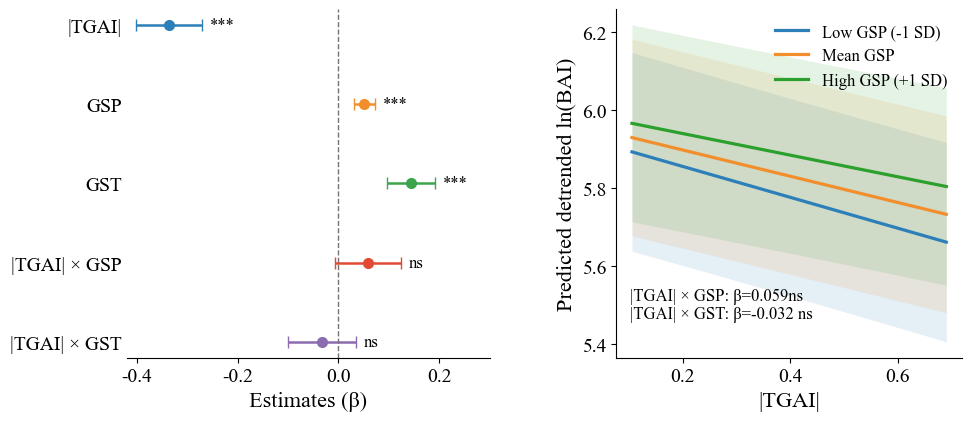

In [15]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import statsmodels.formula.api as smf
# ==================== Data ====================
df=df_me_bai_tgai[['site','Year','Abs_TGAI','BAI','Tree_Speci','GSP','GST']].copy()
df=df.replace([np.inf,-np.inf],np.nan).dropna()
df=df[(df.BAI>0)&(df.Abs_TGAI>=0)].copy()
df['site']=df.site.astype(str);df['Tree_Speci']=df.Tree_Speci.astype(str);df['log_BAI']=np.log(df.BAI)
print('Observations =',len(df))
print('Sites =',df.site.nunique())
print('Species =',df.Tree_Speci.nunique())

# ==================== Site-specific detrending ====================
def detrend_by_site(data,var):
    out=pd.Series(index=data.index,dtype=float)
    for site,idx in data.groupby('site').groups.items():
        g=data.loc[idx].sort_values('Year')
        x=g.Year.values.astype(float);y=g[var].values.astype(float)
        slope,_=np.polyfit(x,y,1)
        out.loc[g.index]=y-slope*(x-x.mean())
    return out
df['log_BAI_dt']=detrend_by_site(df,'log_BAI')
df['Abs_TGAI_dt']=detrend_by_site(df,'Abs_TGAI')
df['GSP_dt']=detrend_by_site(df,'GSP')
df['GST_dt']=detrend_by_site(df,'GST')

# ==================== Trend check ====================
def annual_trend(var):
    annual=df.groupby('Year')[var].mean().reset_index()
    m=smf.ols(f'{var} ~ Year',data=annual).fit()
    return m.params['Year'],m.pvalues['Year']

print('\n================ TREND CHECK ================')
for var in ['log_BAI','log_BAI_dt','Abs_TGAI','Abs_TGAI_dt','GSP','GSP_dt','GST','GST_dt']:
    slope,p=annual_trend(var)
    print(f'{var:15s}: slope={slope: .6f}, p={p:.4g}')

# ==================== Center / standardize ====================
tgai_mean=df.Abs_TGAI_dt.mean();gsp_mean,gsp_sd=df.GSP_dt.mean(),df.GSP_dt.std();gst_mean,gst_sd=df.GST_dt.mean(),df.GST_dt.std()
df['Abs_TGAI_c']=df.Abs_TGAI_dt-tgai_mean
df['GSP_z']=(df.GSP_dt-gsp_mean)/gsp_sd
df['GST_z']=(df.GST_dt-gst_mean)/gst_sd

print(f'\nDetrended |TGAI| mean = {tgai_mean:.4f}')
print(f'Detrended GSP mean ± SD = {gsp_mean:.2f} ± {gsp_sd:.2f} mm')
print(f'Detrended GST mean ± SD = {gst_mean:.2f} ± {gst_sd:.2f} °C')

# ==================== Mixed model ====================
model=smf.mixedlm('log_BAI_dt ~ Abs_TGAI_c*GSP_z + Abs_TGAI_c*GST_z',df,groups=df['Tree_Speci'],re_formula='1',vc_formula={'site':'0+C(site)'})
res=model.fit(reml=False,method='lbfgs',maxiter=5000)
print('\n================ DETRENDED MIXED MODEL ================')
print(res.summary())

# ==================== Model performance ====================
fixed_pred=model.exog@res.fe_params.values
var_fixed=np.var(fixed_pred,ddof=1);var_species=float(res.cov_re.iloc[0,0]);var_site=float(res.vcomp[0]);var_resid=float(res.scale)
var_total=var_fixed+var_species+var_site+var_resid
R2_m=var_fixed/var_total;R2_c=(var_fixed+var_species+var_site)/var_total

print('\n================ MODEL PERFORMANCE ================')
print(f'LogLik = {res.llf:.2f}')
print(f'AIC = {res.aic:.2f}')
print(f'BIC = {res.bic:.2f}')
print(f'Marginal R² = {R2_m:.3f}')
print(f'Conditional R² = {R2_c:.3f}')
print(f'Species variance = {var_species:.4f}')
print(f'Site variance = {var_site:.4f}')
print(f'Residual variance = {var_resid:.4f}')

def star(p):
    if p<0.001:return '***'
    if p<0.01:return '**'
    if p<0.05:return '*'
    return 'ns'

# ==================== Fixed effects ====================
terms=['Abs_TGAI_c','GSP_z','GST_z','Abs_TGAI_c:GSP_z','Abs_TGAI_c:GST_z']
labels=['|TGAI|','GSP','GST','|TGAI| × GSP','|TGAI| × GST']
rows=[]
for term,label in zip(terms,labels):
    ci=res.conf_int().loc[term]
    rows.append([label,res.params[term],res.bse[term],ci.iloc[0],ci.iloc[1],res.pvalues[term],star(res.pvalues[term])])
coef=pd.DataFrame(rows,columns=['Variable','Beta','SE','CI_low','CI_high','P','Sig'])

print('\n================ FIXED EFFECTS ================')
print(coef.round(4).to_string(index=False))

# ==================== Simple slopes ====================
b0=res.params['Abs_TGAI_c'];b_gsp=res.params['Abs_TGAI_c:GSP_z']
print('\n================ SIMPLE SLOPES ================')
for z,name in [(-1,'Low GSP (-1 SD)'),(0,'Mean GSP'),(1,'High GSP (+1 SD)')]:
    slope=b0+b_gsp*z
    print(f'{name:18s}: |TGAI| slope on detrended ln(BAI) = {slope:.4f}')

# ==================== Prediction ====================
x=np.linspace(df.Abs_TGAI_dt.quantile(.01),df.Abs_TGAI_dt.quantile(.99),250);xc=x-tgai_mean
fe_names=['Intercept','Abs_TGAI_c','GSP_z','Abs_TGAI_c:GSP_z','GST_z','Abs_TGAI_c:GST_z']
beta=res.params[fe_names].values;cov=res.cov_params().loc[fe_names,fe_names].values

def predict_curve(gsp_z):
    X=np.column_stack([np.ones(len(x)),xc,np.full(len(x),gsp_z),xc*gsp_z,np.zeros(len(x)),np.zeros(len(x))])
    eta=X@beta
    se=np.sqrt(np.maximum(np.einsum('ij,jk,ik->i',X,cov,X),0))
    return eta,eta-1.96*se,eta+1.96*se

# ==================== Plot ====================
fig,axs=plt.subplots(1,2,figsize=(10,4.5),gridspec_kw={'width_ratios':[1.05,1]})

ax=axs[0]
colors=['#2C7FB8','#F28E2B','#3BA44D','#E34A33','#8C6BB1']
y=np.arange(len(coef))[::-1]
for yi,row,c in zip(y,coef.itertuples(),colors):
    ax.errorbar(row.Beta,yi,xerr=[[row.Beta-row.CI_low],[row.CI_high-row.Beta]],fmt='o',ms=7,lw=1.8,capsize=4,color=c,ecolor=c)
    ax.text(row.CI_high+0.016,yi,row.Sig,ha='left',va='center',fontsize=12)
ax.axvline(0,color='0.45',ls='--',lw=1)
ax.set_yticks(y);ax.set_yticklabels(coef.Variable)
ax.set_xlabel('Estimates (β)')
ax.set_xlim(-0.42,0.30)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False);ax.spines['left'].set_visible(False)
ax.tick_params(axis='y',length=0)

ax=axs[1]
gsp_levels=[(-1,'Low GSP (-1 SD)','#2C7FB8'),(0,'Mean GSP','#F28E2B'),(1,'High GSP (+1 SD)','#2CA02C')]
for level,label,c in gsp_levels:
    pred,lo,hi=predict_curve(level)
    ax.plot(x,pred,lw=2.3,color=c,label=label)
    ax.fill_between(x,lo,hi,color=c,alpha=.12,lw=0)

p1=res.pvalues['Abs_TGAI_c:GSP_z'];p2=res.pvalues['Abs_TGAI_c:GST_z']
ax.text(.04,.20,f'|TGAI| × GSP: β={res.params["Abs_TGAI_c:GSP_z"]:.3f}{star(p1)}\n|TGAI| × GST: β={res.params["Abs_TGAI_c:GST_z"]:.3f} {star(p2)}',
        transform=ax.transAxes,ha='left',va='top',fontsize=12)
ax.set_xlabel('|TGAI|')
ax.set_ylabel('Predicted detrended ln(BAI)')
ax.legend(frameon=False,loc='upper right',fontsize=12)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.tight_layout(w_pad=3)
coef.to_csv(TABLE_DIR / "Table_S3_detrended_mixed_model_coefficients.csv", index=False)
plt.savefig(FIGURE_DIR / "Figure_S7_detrended_BAI_TGAI_model.png", dpi=600, bbox_inches="tight")
plt.show()

## 7. Load sensitivity-analysis data


In [16]:
import os
import pandas as pd
folder = SENSITIVITY_BAI_DIR
df_list = []
for file in os.listdir(folder):
    if file.endswith("_mean.csv"):
        file_path = os.path.join(folder, file)
        site = file.replace("BAI_", "").replace("_mean.csv", "")
        df = pd.read_csv(file_path)
        df = df.rename(columns={"Mean_BAI": "BAI"})
        df["site"] = site
        df = df[["Year", "site", "BAI"]]
        df_list.append(df)
if not df_list:
    raise FileNotFoundError(f"No site-level mean BAI files were found in {folder}")
df_bai = pd.concat(df_list, ignore_index=True)
df_bai = df_bai.sort_values(["site", "Year"]).reset_index(drop=True)


In [17]:
df_bai1901 = df_bai[df_bai["Year"] >= START_YEAR].reset_index(drop=True)
df_TGAIsite = pd.read_csv(SENSITIVITY_TGAI_FILE)
df_TGAI_mean = (df_TGAIsite.groupby(["site", "Year"], as_index=False)
    .agg({
        "Abs_TGAI": "mean",  
        "AI": "mean"      
    })
)

In [18]:
df_TGAI_mean['site'] = df_TGAI_mean['site'].str.lower()
df_bai1901['site'] = df_bai1901['site'].str.lower()
df_bai1901 = df_bai1901[df_bai1901['Year'] <= END_YEAR]
df_me_bai_tgai=pd.merge(df_TGAI_mean, df_bai1901, left_on=['site', 'Year'], right_on=['site', 'Year'], how='inner')
df_site = pd.read_csv(SENSITIVITY_SITE_FILE)
if "site" not in df_site.columns and "Site_ID" in df_site.columns:
    df_site = df_site.rename(columns={"Site_ID": "site"})
df_site["site"] = df_site["site"].astype(str).str.lower()
site_species = df_site[["site", "Tree_Speci", "Latitude", "Longitude"]].drop_duplicates("site")
df_me_bai_tgai = df_me_bai_tgai.merge(site_species,on='site',how='left')


## 8. Extract climate for the sensitivity analysis


In [19]:
import numpy as np,pandas as pd,xarray as xr
if not hasattr(np, "alen"):
    np.alen = lambda a: len(a)
pre_path = CRU_PRE
tmp_path = CRU_TMP

# Growing season: March-October
GS_MONTHS = GROWING_SEASON_MONTHS

# ============================================================
# 1. Site information
# ============================================================
sites=df_me_bai_tgai[['site','Latitude','Longitude']].drop_duplicates('site').copy()
sites=sites.sort_values('site').reset_index(drop=True)

print('Sites =',len(sites))
print(sites.head())

# ============================================================
# 2. Open CRU data
# ============================================================
ds_pre=xr.open_dataset(pre_path)
ds_tmp=xr.open_dataset(tmp_path)

print('\nPRE:')
print(ds_pre)
print('\nTMP:')
print(ds_tmp)

# CRU TS variables normally: pre / tmp
pre=ds_pre['pre']
tmp=ds_tmp['tmp']

# coordinate names
lat_name='lat' if 'lat' in pre.coords else 'latitude'
lon_name='lon' if 'lon' in pre.coords else 'longitude'

# ============================================================
# 3. Handle longitude convention
# ============================================================
site_lon=sites['Longitude'].values.copy()

# If dataset longitude is 0~360, convert site longitude
if float(pre[lon_name].min())>=0:
    site_lon=np.mod(site_lon,360)

site_lat=xr.DataArray(sites['Latitude'].values,dims='site',coords={'site':sites['site'].values})
site_lon=xr.DataArray(site_lon,dims='site',coords={'site':sites['site'].values})

# ============================================================
# 4. Extract nearest CRU grid cell for each site
# ============================================================
pre_site=pre.sel({lat_name:site_lat,lon_name:site_lon},method='nearest')
tmp_site=tmp.sel({lat_name:site_lat,lon_name:site_lon},method='nearest')

# only load selected site data, not full global arrays
pre_site=pre_site.load()
tmp_site=tmp_site.load()

print('\nExtracted PRE shape:',pre_site.shape)
print('Extracted TMP shape:',tmp_site.shape)

# ============================================================
# 5. Growing-season annual GSP / GST
# ============================================================
pre_gs=pre_site.where(pre_site.time.dt.month.isin(GS_MONTHS),drop=True)
tmp_gs=tmp_site.where(tmp_site.time.dt.month.isin(GS_MONTHS),drop=True)

# GSP: sum monthly precipitation
GSP=pre_gs.groupby('time.year').sum('time',skipna=True)

# GST: mean monthly temperature
GST=tmp_gs.groupby('time.year').mean('time',skipna=True)

# ============================================================
# 6. Convert to dataframe
# ============================================================
gsp_df=GSP.to_dataframe(name='GSP').reset_index()[['site','year','GSP']]
gst_df=GST.to_dataframe(name='GST').reset_index()[['site','year','GST']]

climate=gsp_df.merge(gst_df,on=['site','year'],how='outer')
climate=climate.rename(columns={'year':'Year'})

print('\nClimate table:')
print(climate.head())
print(climate[['GSP','GST']].describe())

# ============================================================
# 7. Merge back to df_me_bai_tgai
# ============================================================
df_me_bai_tgai=df_me_bai_tgai.merge(
    climate,
    on=['site','Year'],
    how='left'
)
print('\nFinal dataframe:')
print(df_me_bai_tgai.head())
print('\nMissing GSP =',df_me_bai_tgai['GSP'].isna().sum())
print('Missing GST =',df_me_bai_tgai['GST'].isna().sum())
# ============================================================
# 8. Basic check
# ============================================================
print('\nGSP range:',df_me_bai_tgai.GSP.min(),'~',df_me_bai_tgai.GSP.max(),'mm')
print('GST range:',df_me_bai_tgai.GST.min(),'~',df_me_bai_tgai.GST.max(),'°C')
ds_pre.close()
ds_tmp.close()

Sites = 67
    site  Latitude  Longitude
0  ak048     67.12    -150.08
1  ak049     67.15    -150.08
2  ak050     67.15    -149.13
3  ak054     63.10    -150.00
4  ak056     63.12    -149.00

PRE:
<xarray.Dataset>
Dimensions:  (lon: 720, lat: 360, time: 1464)
Coordinates:
  * lon      (lon) float32 -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
  * lat      (lat) float32 -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * time     (time) datetime64[ns] 1901-01-16 1901-02-15 ... 2022-12-16
Data variables:
    pre      (time, lat, lon) float32 ...
    stn      (time, lat, lon) float64 ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.07 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2304141047. Data generated from:pre.2304141039.dtb
    history:      Fri 14 Apr 12:49:03 BST 2023 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comm

## 9. Sensitivity mixed-effects model (Figure S10c-d and Table S4)


Observations = 6446
Sites = 67
Species = 19
|TGAI| mean = 0.3565
GSP mean ± SD = 457.29 ± 245.47 mm
GST mean ± SD = 5.62 ± 5.41 °C
Year range = 1901-2000

================ MIXED MODEL ================
           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  log_BAI   
No. Observations:  6446     Method:              ML        
No. Groups:        19       Scale:               0.1347    
Min. group size:   75       Log-Likelihood:      -2874.3085
Max. group size:   1198     Converged:           Yes       
Mean group size:   339.3                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         5.822    0.128 45.572 0.000  5.571  6.072
Abs_TGAI_c       -0.295    0.046 -6.368 0.000 -0.386 -0.204
GSP_z             0.042    0.014  3.023 0.003  0.015  0.069
Abs_TGAI_c:GSP_z  0.168    0.0

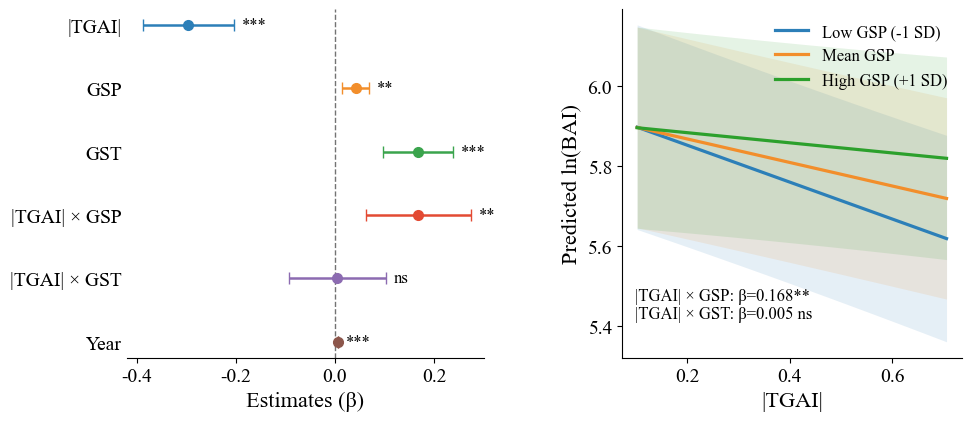

In [20]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import statsmodels.formula.api as smf
plt.rcParams['font.family']='Times New Roman'
plt.rcParams['font.size']=16
plt.rcParams['xtick.labelsize']=14
plt.rcParams['ytick.labelsize']=14
plt.rcParams.update({'font.family':'Times New Roman','font.serif':['Times New Roman'],
                     'mathtext.fontset':'custom','mathtext.rm':'Times New Roman',
                     'mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold',
                     'mathtext.sf':'Times New Roman','axes.unicode_minus':False})
# ==================== Data ====================
df=df_me_bai_tgai[['site','Year','Abs_TGAI','BAI','Tree_Speci','GSP','GST']].copy()
df=df.replace([np.inf,-np.inf],np.nan).dropna()
df=df[(df.BAI>0)&(df.Abs_TGAI>=0)].copy()
df['site']=df.site.astype(str);df['Tree_Speci']=df.Tree_Speci.astype(str);df['log_BAI']=np.log(df.BAI)

tgai_mean=df.Abs_TGAI.mean();gsp_mean,gsp_sd=df.GSP.mean(),df.GSP.std();gst_mean,gst_sd=df.GST.mean(),df.GST.std();year_mean=df.Year.mean()
df['Abs_TGAI_c']=df.Abs_TGAI-tgai_mean
df['GSP_z']=(df.GSP-gsp_mean)/gsp_sd
df['GST_z']=(df.GST-gst_mean)/gst_sd
df['Year_c']=df.Year-year_mean

print('Observations =',len(df))
print('Sites =',df.site.nunique())
print('Species =',df.Tree_Speci.nunique())
print(f'|TGAI| mean = {tgai_mean:.4f}')
print(f'GSP mean ± SD = {gsp_mean:.2f} ± {gsp_sd:.2f} mm')
print(f'GST mean ± SD = {gst_mean:.2f} ± {gst_sd:.2f} °C')
print(f'Year range = {df.Year.min()}-{df.Year.max()}')

# ==================== Mixed model ====================
model=smf.mixedlm('log_BAI ~ Abs_TGAI_c*GSP_z + Abs_TGAI_c*GST_z + Year_c',df,groups=df['Tree_Speci'],re_formula='1',vc_formula={'site':'0+C(site)'})
res=model.fit(reml=False,method='lbfgs',maxiter=5000)
print('\n================ MIXED MODEL ================')
print(res.summary())

# ==================== Model performance ====================
fixed_pred=model.exog@res.fe_params.values
var_fixed=np.var(fixed_pred,ddof=1);var_species=float(res.cov_re.iloc[0,0]);var_site=float(res.vcomp[0]);var_resid=float(res.scale)
var_total=var_fixed+var_species+var_site+var_resid
R2_m=var_fixed/var_total;R2_c=(var_fixed+var_species+var_site)/var_total
print('\n================ MODEL PERFORMANCE ================')
print(f'LogLik = {res.llf:.2f}')
print(f'AIC = {res.aic:.2f}')
print(f'BIC = {res.bic:.2f}')
print(f'Marginal R² = {R2_m:.3f}')
print(f'Conditional R² = {R2_c:.3f}')
print(f'Species variance = {var_species:.4f}')
print(f'Site variance = {var_site:.4f}')
print(f'Residual variance = {var_resid:.4f}')

def star(p):
    if p<0.001:return '***'
    if p<0.01:return '**'
    if p<0.05:return '*'
    return 'ns'

# ==================== Fixed effects ====================
terms=['Abs_TGAI_c','GSP_z','GST_z','Abs_TGAI_c:GSP_z','Abs_TGAI_c:GST_z','Year_c']
labels=['|TGAI|','GSP','GST','|TGAI| × GSP','|TGAI| × GST','Year']
rows=[]
for term,label in zip(terms,labels):
    ci=res.conf_int().loc[term]
    rows.append([label,res.params[term],res.bse[term],ci.iloc[0],ci.iloc[1],res.pvalues[term],star(res.pvalues[term])])
coef=pd.DataFrame(rows,columns=['Variable','Beta','SE','CI_low','CI_high','P','Sig'])
print('\n================ FIXED EFFECTS ================')
print(coef.round(4).to_string(index=False))

# ==================== Simple slopes ====================
b0=res.params['Abs_TGAI_c'];b_gsp=res.params['Abs_TGAI_c:GSP_z']
print('\n================ SIMPLE SLOPES ================')
for z,name in [(-1,'Low GSP (-1 SD)'),(0,'Mean GSP'),(1,'High GSP (+1 SD)')]:
    slope=b0+b_gsp*z
    print(f'{name:18s}: |TGAI| slope on ln(BAI) = {slope:.4f}')

# ==================== Prediction ====================
x=np.linspace(df.Abs_TGAI.quantile(.01),df.Abs_TGAI.quantile(.99),250);xc=x-tgai_mean
fe_names=['Intercept','Abs_TGAI_c','GSP_z','Abs_TGAI_c:GSP_z','GST_z','Abs_TGAI_c:GST_z','Year_c']
beta=res.params[fe_names].values;cov=res.cov_params().loc[fe_names,fe_names].values

def predict_curve(gsp_z):
    X=np.column_stack([np.ones(len(x)),xc,np.full(len(x),gsp_z),xc*gsp_z,np.zeros(len(x)),np.zeros(len(x)),np.zeros(len(x))])
    eta=X@beta
    se=np.sqrt(np.maximum(np.einsum('ij,jk,ik->i',X,cov,X),0))
    return eta,eta-1.96*se,eta+1.96*se

# ==================== Plot ====================
fig,axs=plt.subplots(1,2,figsize=(10,4.5),gridspec_kw={'width_ratios':[1.05,1]})

ax=axs[0]
colors=['#2C7FB8','#F28E2B','#3BA44D','#E34A33','#8C6BB1','#8C564B']
y=np.arange(len(coef))[::-1]
for yi,row,c in zip(y,coef.itertuples(),colors):
    ax.errorbar(row.Beta,yi,xerr=[[row.Beta-row.CI_low],[row.CI_high-row.Beta]],fmt='o',ms=7,lw=1.8,capsize=4,color=c,ecolor=c)
    ax.text(row.CI_high+0.016,yi,row.Sig,ha='left',va='center',fontsize=12)
ax.axvline(0,color='0.45',ls='--',lw=1)
ax.set_yticks(y);ax.set_yticklabels(coef.Variable)
ax.set_xlabel('Estimates (β)')
ax.set_xlim(-0.42,0.30)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False);ax.spines['left'].set_visible(False)
ax.tick_params(axis='y',length=0)

ax=axs[1]
gsp_levels=[(-1,'Low GSP (-1 SD)','#2C7FB8'),(0,'Mean GSP','#F28E2B'),(1,'High GSP (+1 SD)','#2CA02C')]
for level,label,c in gsp_levels:
    pred,lo,hi=predict_curve(level)
    ax.plot(x,pred,lw=2.3,color=c,label=label)
    ax.fill_between(x,lo,hi,color=c,alpha=.12,lw=0)

p1=res.pvalues['Abs_TGAI_c:GSP_z'];p2=res.pvalues['Abs_TGAI_c:GST_z']
ax.text(.04,.20,f'|TGAI| × GSP: β={res.params["Abs_TGAI_c:GSP_z"]:.3f}{star(p1)}\n|TGAI| × GST: β={res.params["Abs_TGAI_c:GST_z"]:.3f} {star(p2)}',
        transform=ax.transAxes,ha='left',va='top',fontsize=12)
ax.set_xlabel('|TGAI|')
ax.set_ylabel('Predicted ln(BAI)')
ax.legend(frameon=False,loc='upper right',fontsize=12)
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.tight_layout(w_pad=3)
coef.to_csv(SENSITIVITY_TABLE_DIR / "Table_S4_mixed_model_coefficients.csv", index=False)
plt.savefig(SENSITIVITY_FIGURE_DIR / "Figure_S10c_d_BAI_TGAI_mixed_model.png", dpi=600, bbox_inches="tight")
plt.show()
